# Lab 3: Classification — Solutions

In this lab we implement logistic regression and a linear SVM from scratch with NumPy, and use kernels to get curved decision boundaries. Part 2, comparing classifiers on a real marketing dataset, is homework.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score
plt.style.use("seaborn-v0_8")

## Helpers

The three functions below are given. Run the three cells and move on.

**`add_intercept`** adds the column of ones that carries the intercept $\beta_0$, as in Lab 2.

In [2]:
def add_intercept(X):
    """Return X with a first column of ones, shape (num_samples, num_features + 1)."""
    ones = np.ones((X.shape[0], 1))
    return np.hstack([ones, X])

**`accuracy`** is the share of correct predictions.

In [3]:
def accuracy(y_true, y_pred):
    """Share of predictions equal to the true labels."""
    return np.mean(y_true == y_pred)

**`plot_decision_boundary`** colours the plane by the class a model predicts, and draws the data points on top (Part 1).

In [4]:
def plot_decision_boundary(model, X, y, title=None, ax=None):
    """Colour the plane by the class that model predicts, and draw the points (X, y) on top.

    model: any fitted model with a predict method (ours or scikit-learn's)
    ax:    optional matplotlib axis, to draw inside a grid of subplots
    """
    # create a new figure if no axis is given
    if ax is None:
        ax = plt.figure(figsize=(6, 5)).gca()

    # grid of points covering the data, with a margin of 1
    x1 = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300)
    x2 = np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300)
    grid_1, grid_2 = np.meshgrid(x1, x2)
    grid = np.column_stack([grid_1.ravel(), grid_2.ravel()])

    # predicted class at every grid point, drawn as two coloured regions
    classes = model.predict(grid).reshape(grid_1.shape)
    ax.contourf(grid_1, grid_2, classes, levels=[-0.5, 0.5, 1.5], cmap="coolwarm", alpha=0.3)

    # data points on top, coloured by their true class
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k", s=25)
    ax.set_xlabel("feature 1")
    ax.set_ylabel("feature 2")
    if title is not None:
        ax.set_title(title)

## Part 1: Linear and kernel classifiers on a toy dataset

Each point has two features and a label, 0 or 1.

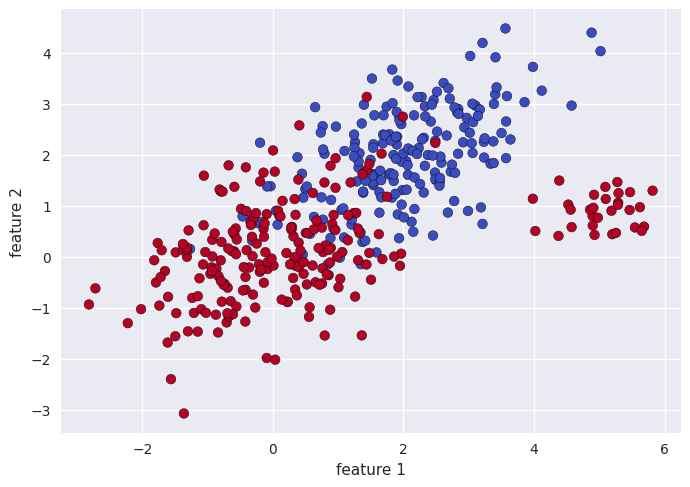

In [5]:
data = np.loadtxt("NLS_2.csv", delimiter=",")
X = data[:, :2]  # the two features
y = data[:, 2]   # the label, 0 or 1

plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k")
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.show()

We split the data in three parts:
- **train** (60%): to fit the models;
- **validation** (20%): to choose hyperparameters, such as $C$ and $\gamma$ for the SVM;
- **test** (20%): used only once at the end, to measure the accuracy on data never seen before.

Choosing hyperparameters on the test set would make the test score too optimistic.

In [6]:
# stratify keeps the same proportion of 0 and 1 in every part
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, random_state=0, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=0, stratify=y_tmp)
print("train:", len(y_train), "| validation:", len(y_val), "| test:", len(y_test))

train: 258 | validation: 86 | test: 86


### 1.1 Logistic regression

Logistic regression uses the same linear score as in Lab 2, $X\beta$, where $X$ is the data with a column of ones, and turns it into a probability with the **sigmoid**:
$$
p = \sigma(X\beta), \qquad \sigma(z) = \frac{1}{1 + e^{-z}} .
$$
$p_i$ is the predicted probability that point $i$ is in class 1, and we predict class 1 when $p_i \ge 0.5$.

The best $\beta$ minimises the **log loss**, which is small when each $p_i$ is close to the true label $y_i$:
$$
L(\beta) = -\frac{1}{n} \sum_{i=1}^{n} \Big[ y_i \log p_i + (1 - y_i) \log (1 - p_i) \Big] .
$$
There is no formula for the minimum, so we use **gradient descent**, as for lasso in Lab 2. The gradient of the log loss is
$$
\nabla L(\beta) = \frac{1}{n} X^T (p - y),
$$
and each step moves $\beta$ a little against it: $\beta \leftarrow \beta - \eta\, \nabla L(\beta)$, where $\eta$ is the learning rate.
(The lecture fits the same loss with IRLS, which reaches the same $\beta$ in fewer steps.)

**Exercise 1.** Complete `LogisticRegression`.

In [7]:
class LogisticRegression:
    """Logistic regression trained by gradient descent on the log loss."""

    def __init__(self, learning_rate=0.5, n_iter=5000):
        self.learning_rate = learning_rate  # step size eta
        self.n_iter = n_iter                # number of gradient steps
        self.coef_ = None                   # will hold [beta_0, beta_1, ..., beta_d]

    def sigmoid(self, z):
        """Sigmoid 1 / (1 + exp(-z)), applied to every entry of the array z."""
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        """Fit the data (X, y) and store the coefficients in self.coef_.

        Parameters:
        -----------
        X: (num_samples, num_features) np.array
            Design matrix
        y: (num_samples,) np.array
            Labels, 0 or 1
        """
        # Step 1: add the column of ones
        X_aug = add_intercept(X)  # shape (num_samples, num_features + 1)

        # Step 2: start from beta = 0
        beta = np.zeros(X_aug.shape[1])

        # Step 3: gradient descent
        for _ in range(self.n_iter):
            # a) probabilities of class 1
            p = self.sigmoid(X_aug @ beta)  # shape (num_samples,)

            # b) gradient of the log loss
            gradient = X_aug.T @ (p - y) / len(y)  # shape (num_features + 1,)

            # c) gradient step
            beta = beta - self.learning_rate * gradient

        # Step 4: store the coefficients
        self.coef_ = beta
        return self

    def predict_proba(self, X):
        """Probability of class 1 for every row of X."""
        # Step 1: add the column of ones
        X_aug = add_intercept(X)

        # Step 2: sigmoid of the linear score
        return self.sigmoid(X_aug @ self.coef_)

    def predict(self, X):
        """Predicted class, 0 or 1, for every row of X."""
        return np.where(self.predict_proba(X) >= 0.5, 1, 0)

Fit the model and draw its decision boundary:

Coefficients:        [ 2.301 -0.209 -1.836]
Train accuracy:       0.814
Validation accuracy:  0.756


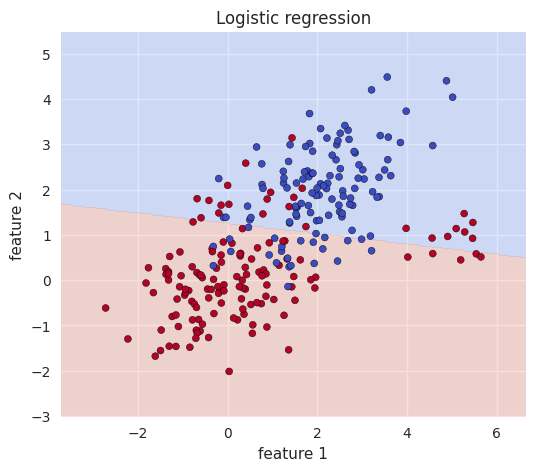

In [8]:
logistic = LogisticRegression()
logistic.fit(X_train, y_train)

print("Coefficients:       ", np.round(logistic.coef_, 3))
print(f"Train accuracy:       {accuracy(y_train, logistic.predict(X_train)):.3f}")
print(f"Validation accuracy:  {accuracy(y_val, logistic.predict(X_val)):.3f}")
plot_decision_boundary(logistic, X_train, y_train, title="Logistic regression")
plt.show()

### 1.2 Linear SVM

A linear SVM uses the same score, $f(x_i) = (X\beta)_i$, and predicts class 1 when $f(x_i) \ge 0$. Only the loss changes, as on the "Hinge, log loss, squares" slide.
With the labels written $s_i = +1$ for class 1 and $s_i = -1$ for class 0, the soft-margin SVM minimises
$$
L(\beta) = \frac{1}{2} \|w\|^2 + C \sum_{i=1}^{n} \max\big(0,\ 1 - s_i f(x_i)\big),
$$
where $w$ is $\beta$ without the intercept $\beta_0$.
- The **hinge loss** $\max(0, 1 - s_i f(x_i))$ is 0 for points on the correct side with a margin $s_i f(x_i) \ge 1$. Points inside the margin or on the wrong side are penalised.
- $\frac{1}{2}\|w\|^2$ keeps the margin wide. It is the ridge penalty of Lab 2, and the intercept is not penalised.
- $C$ sets how much the penalised points cost compared with a wide margin.

We minimise it by gradient descent too. Only the **violating** points, those with $s_i f(x_i) < 1$, enter the gradient of the hinge part:
$$
\nabla L(\beta) = w_0 - C \sum_{i \text{ violating}} s_i\, x_i ,
$$
where $w_0$ is $\beta$ with its intercept entry set to 0, and $x_i$ is row $i$ of $X$.

**Exercise 2.** Complete `LinearSVM`. The structure is the same as `LogisticRegression`: only the gradient changes.

In [9]:
class LinearSVM:
    """Linear soft-margin SVM trained by gradient descent on the hinge loss."""

    def __init__(self, C=1.0, learning_rate=0.001, n_iter=5000):
        self.C = C                          # cost of the points inside the margin or misclassified
        self.learning_rate = learning_rate  # step size
        self.n_iter = n_iter                # number of gradient steps
        self.coef_ = None                   # will hold [beta_0, beta_1, ..., beta_d]

    def fit(self, X, y):
        """Fit the data (X, y) and store the coefficients in self.coef_.

        Parameters:
        -----------
        X: (num_samples, num_features) np.array
            Design matrix
        y: (num_samples,) np.array
            Labels, 0 or 1
        """
        # Step 1: add the column of ones
        X_aug = add_intercept(X)  # shape (num_samples, num_features + 1)

        # Step 2: labels -1 / +1
        s = 2 * y - 1

        # Step 3: start from beta = 0
        beta = np.zeros(X_aug.shape[1])

        # Step 4: gradient descent
        for _ in range(self.n_iter):
            # a) margins of all points
            margins = s * (X_aug @ beta)  # shape (num_samples,)

            # b) points inside the margin or on the wrong side
            violating = margins < 1

            # c) gradient of the penalty 1/2 ||w||^2 (the intercept is not penalised)
            w0 = beta.copy()
            w0[0] = 0

            # d) gradient of the hinge part: only the violating points count
            hinge_gradient = -self.C * X_aug[violating].T @ s[violating]

            # e) gradient step
            beta = beta - self.learning_rate * (w0 + hinge_gradient)

        # Step 5: store the coefficients
        self.coef_ = beta
        return self

    def decision_function(self, X):
        """Score f(x) for every row of X: class 1 when the score is >= 0."""
        # Step 1: add the column of ones
        X_aug = add_intercept(X)

        # Step 2: linear score
        return X_aug @ self.coef_

    def predict(self, X):
        """Predicted class, 0 or 1, for every row of X."""
        return np.where(self.decision_function(X) >= 0, 1, 0)

Fit the SVM and compare it with logistic regression. As a check, scikit-learn's `SVC(kernel="linear")` should find almost the same coefficients:

Coefficients, ours:         [ 1.374 -0.154 -1.111]
Coefficients, scikit-learn: [ 1.374 -0.154 -1.112]
Validation accuracy, logistic regression: 0.756
Validation accuracy, linear SVM:          0.744


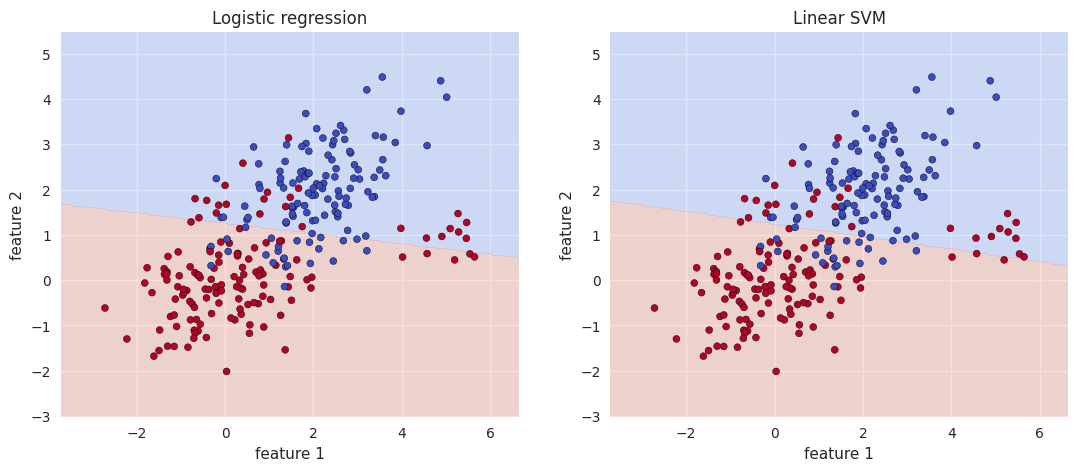

In [10]:
linear_svm = LinearSVM(C=1.0)
linear_svm.fit(X_train, y_train)

sklearn_svm = SVC(kernel="linear", C=1.0)
sklearn_svm.fit(X_train, y_train)
print("Coefficients, ours:        ", np.round(linear_svm.coef_, 3))
print("Coefficients, scikit-learn:", np.round(np.r_[sklearn_svm.intercept_, sklearn_svm.coef_[0]], 3))
print(f"Validation accuracy, logistic regression: {accuracy(y_val, logistic.predict(X_val)):.3f}")
print(f"Validation accuracy, linear SVM:          {accuracy(y_val, linear_svm.predict(X_val)):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_decision_boundary(logistic, X_train, y_train, title="Logistic regression", ax=axes[0])
plot_decision_boundary(linear_svm, X_train, y_train, title="Linear SVM", ax=axes[1])
plt.show()

Both boundaries are straight lines, and both models make many mistakes: these classes cannot be separated by a line.

### 1.3 Kernels

The **kernel trick** lets the SVM draw curved boundaries. With the RBF kernel, two hyperparameters matter:
- $C$: as before, how much the points inside the margin or on the wrong side cost;
- $\gamma$: how far the influence of one training point reaches. A large $\gamma$ gives a very local, wiggly boundary.

Kernel SVMs are solved through the dual problem of the lecture, so here we use scikit-learn's `SVC`. The effect of $C$ and $\gamma$:

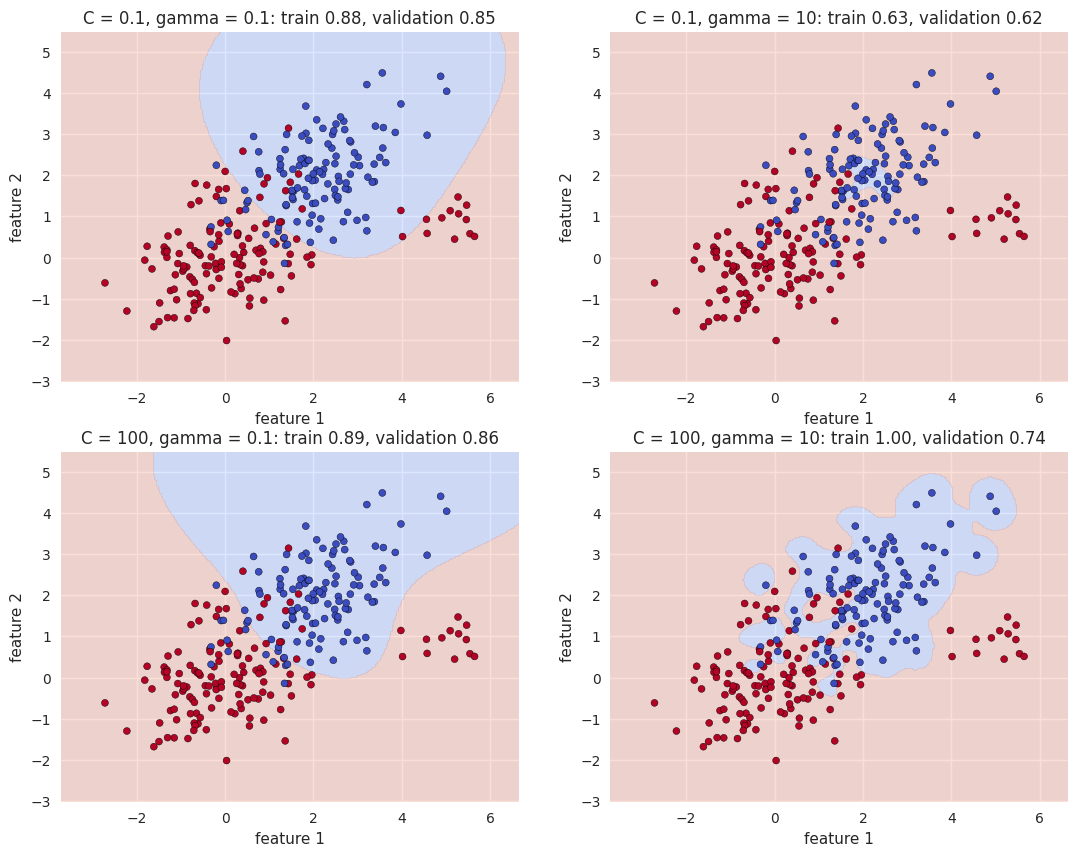

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (C, gamma) in zip(axes.ravel(), [(0.1, 0.1), (0.1, 10), (100, 0.1), (100, 10)]):
    model = SVC(kernel="rbf", C=C, gamma=gamma)
    model.fit(X_train, y_train)
    title = (f"C = {C}, gamma = {gamma}: train {accuracy(y_train, model.predict(X_train)):.2f}, "
             f"validation {accuracy(y_val, model.predict(X_val)):.2f}")
    plot_decision_boundary(model, X_train, y_train, title=title, ax=ax)
plt.show()

- With $\gamma = 0.1$ the boundary is a smooth curve around the blue class, and the validation accuracy (about 0.85) is better than with the straight lines.
- With $\gamma = 10$ each training point only influences its close neighbourhood. With $C = 100$ the SVM draws small islands around the training points: train accuracy 1.00 but validation 0.74, it **overfits**. With $C = 0.1$ it is not pushed to fit the points, and almost the whole plane gets the same class.

So $C$ and $\gamma$ must be chosen on the validation set.

**Exercise 3.** Complete `tune_svm`: try every combination of $C$ and $\gamma$, fit an RBF SVM on the train set, and keep the one with the best accuracy on the validation set (the same search as `least_squares_search` in Lab 2).

In [12]:
def tune_svm(X_train, y_train, X_val, y_val, Cs, gammas):
    """Try an RBF SVM for every C in Cs and every gamma in gammas.

    Returns:
    --------
    best_C, best_gamma: float
        The combination with the best validation accuracy
    best_accuracy: float
    """
    # Step 1: no model tried yet
    best_accuracy = -1

    # Step 2: try every combination of C and gamma
    for C in Cs:
        for gamma in gammas:
            # a) fit on the train set
            model = SVC(kernel="rbf", C=C, gamma=gamma)
            model.fit(X_train, y_train)

            # b) accuracy on the validation set
            val_accuracy = accuracy(y_val, model.predict(X_val))

            # c) keep it if it is the best model so far
            if val_accuracy > best_accuracy:
                best_accuracy = val_accuracy
                best_C = C
                best_gamma = gamma

    # Step 3: the best combination
    return best_C, best_gamma, best_accuracy

Tune the RBF SVM, then compare the three models **once** on the test set:

Best C = 1, best gamma = 0.1, validation accuracy = 0.860
Test accuracy, Logistic regression  0.814
Test accuracy, Linear SVM           0.814
Test accuracy, RBF SVM              0.907


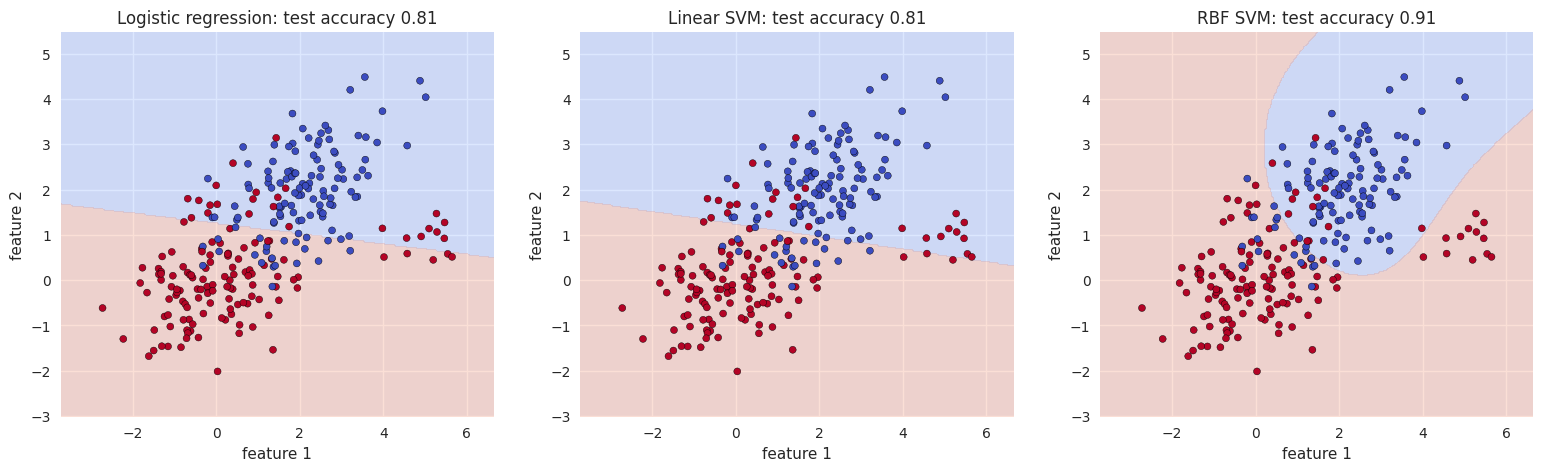

In [13]:
best_C, best_gamma, best_accuracy = tune_svm(X_train, y_train, X_val, y_val,
                                             Cs=[0.1, 1, 10, 100], gammas=[0.01, 0.1, 1, 10])
print(f"Best C = {best_C}, best gamma = {best_gamma}, validation accuracy = {best_accuracy:.3f}")

rbf_svm = SVC(kernel="rbf", C=best_C, gamma=best_gamma)
rbf_svm.fit(X_train, y_train)

final_models = {"Logistic regression": logistic, "Linear SVM": linear_svm, "RBF SVM": rbf_svm}
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (name, model) in zip(axes, final_models.items()):
    test_accuracy = accuracy(y_test, model.predict(X_test))
    print(f"Test accuracy, {name:20s} {test_accuracy:.3f}")
    plot_decision_boundary(model, X_train, y_train, title=f"{name}: test accuracy {test_accuracy:.2f}", ax=ax)
plt.show()

Both linear models reach the same test accuracy (0.81). The RBF SVM bends its boundary around the blue class and reaches 0.91: on these data, the kernel makes the difference.

## Part 2 (homework): Bank marketing

This part is to finish at home: Exercises 4 and 5, then the comparison of the models.

The data comes from phone marketing campaigns of a Portuguese bank. The goal is to predict whether a client subscribes to a term deposit (`y`, yes or no).

| Group | Features |
|---|---|
| Client | `age`, `job`, `marital`, `education`, `default` (credit in default?), `balance` (average yearly balance, €), `housing` (housing loan?), `loan` (personal loan?) |
| Last contact of this campaign | `contact` (type), `day`, `month`, `duration` (seconds) |
| Other | `campaign` (contacts during this campaign), `pdays` (days since the last contact of a previous campaign, −1 if never), `previous` (contacts before this campaign), `poutcome` (outcome of the previous campaign) |

In [14]:
bank = pd.read_csv("bank.csv", sep=";")
print("Rows and columns:", bank.shape)
print(f"Share of clients who subscribed: {(bank['y'] == 'yes').mean():.3f}")
bank.head()

Rows and columns: (4521, 17)
Share of clients who subscribed: 0.115


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


**Preparing the data** (given):
- the target `y` becomes 1 (yes) or 0 (no);
- we drop `duration`: the length of the call is only known once the call is over, when the client has already answered, so it would leak the answer;
- the categorical features (text values, like `job`) become 0/1 columns with **one-hot encoding**: for example, `marital` becomes `marital_divorced`, `marital_married` and `marital_single`.

Then we split the data into train, validation and test sets, as in Part 1.

In [15]:
bank["y"] = (bank["y"] == "yes").astype(int)
bank = bank.drop(columns="duration")

categorical = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]
numerical = ["age", "balance", "day", "campaign", "pdays", "previous"]
bank = pd.get_dummies(bank, columns=categorical, dtype=float)

X = bank.drop(columns="y")
y = bank["y"].values
print("Number of features after one-hot encoding:", X.shape[1])

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, random_state=0, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=0, stratify=y_tmp)
print("train:", len(y_train), "| validation:", len(y_val), "| test:", len(y_test))

Number of features after one-hot encoding: 50
train: 2712 | validation: 904 | test: 905


### 2.1 Scaling

The numerical features have very different ranges: `balance` is in thousands of euros, `campaign` is around 1 to 10. As the lecture says, scale the features first: SVMs and gradient descent are sensitive to the scale.
We **standardise** each numerical column: $(x - \text{mean}) / \text{std}$.
The mean and the standard deviation are computed on the **train set only**, and applied to the three sets, so that nothing from the validation or test sets leaks into training.

**Exercise 4 (homework).** Complete `standardize`.

In [16]:
def standardize(X_train, X_val, X_test, columns):
    """Standardise the given columns with the mean and standard deviation of the train set.

    Parameters:
    -----------
    X_train, X_val, X_test: pandas DataFrames
    columns: list of the column names to standardise

    Returns:
    --------
    The three standardised DataFrames
    """
    # Step 1: statistics of the train set only
    mean = X_train[columns].mean()
    std = X_train[columns].std()

    # Step 2: copies, so that the original tables do not change
    X_train, X_val, X_test = X_train.copy(), X_val.copy(), X_test.copy()

    # Step 3: same transformation for the three sets
    for table in (X_train, X_val, X_test):
        table[columns] = (table[columns] - mean) / std

    # Step 4: the standardised tables
    return X_train, X_val, X_test

In [17]:
X_train, X_val, X_test = standardize(X_train, X_val, X_test, numerical)
print(X_train[numerical].describe().loc[["mean", "std"]].round(2))

# NumPy arrays for the models
X_train, X_val, X_test = X_train.values, X_val.values, X_test.values

      age  balance  day  campaign  pdays  previous
mean -0.0     -0.0 -0.0      -0.0   -0.0       0.0
std   1.0      1.0  1.0       1.0    1.0       1.0


After scaling, every numerical column of the train set has mean 0 and standard deviation 1.

### 2.2 AUC

Only about 11.5% of the clients subscribe. A model that always answers "no" is therefore about 88.5% accurate, without learning anything: accuracy is misleading here.

The **AUC** measures how well a model *ranks* the clients. Every model gives each client a score (for example the probability of class 1), and the AUC is the probability that a randomly chosen client who subscribed gets a higher score than a randomly chosen client who did not. AUC = 1 is a perfect ranking, and AUC = 0.5 is random guessing.

**Exercise 5 (homework).** Complete `auc`.

In [18]:
def auc(y_true, scores):
    """Probability that a random positive (y = 1) gets a higher score than a random negative (y = 0).
    Ties count for one half.

    Parameters:
    -----------
    y_true: (num_samples,) np.array
        Labels, 0 or 1
    scores: (num_samples,) np.array
        Score of class 1 given by a model

    Returns:
    --------
    auc: float
    """
    # Step 1: scores of the positives and of the negatives
    positive = scores[y_true == 1]
    negative = scores[y_true == 0]

    # Step 2: one comparison per (positive, negative) pair
    higher = positive[:, None] > negative[None, :]  # shape (num_positives, num_negatives)
    tied = positive[:, None] == negative[None, :]

    # Step 3: share of pairs ranked correctly, ties count for one half
    return np.mean(higher) + 0.5 * np.mean(tied)

Check: random scores should give an AUC around 0.5 (not exactly, by chance), and your function should match scikit-learn's `roc_auc_score`.

In [19]:
random_scores = np.random.RandomState(0).rand(len(y_val))
print(f"Our AUC:          {auc(y_val, random_scores):.4f}")
print(f"scikit-learn AUC: {roc_auc_score(y_val, random_scores):.4f}")

Our AUC:          0.4521
scikit-learn AUC: 0.4521


### 2.3 Comparing models

We compare our logistic regression from Part 1 with scikit-learn's RBF SVM and the tree ensembles of the second lecture: a **random forest** (many deep trees, averaged) and **gradient boosting** (many small trees, added one after the other).

Each model gives a score of class 1 for every client: the probability for logistic regression and the trees, the decision function for the SVM.

In [20]:
def class1_scores(model, X):
    """Score of class 1 for every row of X: the higher, the more likely the client subscribes."""
    if isinstance(model, SVC):
        return model.decision_function(X)    # SVM: signed distance to the boundary
    if isinstance(model, LogisticRegression):
        return model.predict_proba(X)        # ours: probability of class 1
    return model.predict_proba(X)[:, 1]      # scikit-learn: the second column is the probability of class 1

In [21]:
models = {"logistic regression (ours)": LogisticRegression(),
          "SVM, RBF kernel": SVC(kernel="rbf"),
          "random forest": RandomForestClassifier(random_state=0),
          "gradient boosting": GradientBoostingClassifier(random_state=0)}

print(f"{'always no':28s} validation accuracy = {accuracy(y_val, np.zeros(len(y_val))):.3f}   AUC = 0.500")
validation_auc = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    validation_auc[name] = auc(y_val, class1_scores(model, X_val))
    print(f"{name:28s} validation accuracy = {accuracy(y_val, model.predict(X_val)):.3f}   AUC = {validation_auc[name]:.3f}")

always no                    validation accuracy = 0.885   AUC = 0.500


logistic regression (ours)   validation accuracy = 0.889   AUC = 0.703


SVM, RBF kernel              validation accuracy = 0.895   AUC = 0.696


random forest                validation accuracy = 0.894   AUC = 0.709


gradient boosting            validation accuracy = 0.881   AUC = 0.706


We keep the model with the best validation AUC, and measure its AUC **once** on the test set:

In [22]:
best_name = max(validation_auc, key=validation_auc.get)
best_model = models[best_name]
print("Best model on the validation set:", best_name)
print(f"Test AUC: {auc(y_test, class1_scores(best_model, X_test)):.3f}")

Best model on the validation set: random forest
Test AUC: 0.774
